## Plot df with x and y

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
df_test = pd.read_csv('/home/laura93schade/local/lidar/dname_geo_split_quadrants__polunion:_no__target_lidar__timelim_2000.0__modelset_best_quality__tsp_1.0__polarim_0__colset_withx__uuid_eee626fd-/predictions_test.csv')
df_train = pd.read_csv('/home/laura93schade/local/lidar/dname_geo_split_quadrants__polunion:_no__target_lidar__timelim_2000.0__modelset_best_quality__tsp_1.0__polarim_0__colset_withx__uuid_eee626fd-/predictions_train.csv')

In [3]:
df_test.head()

,x,y,z_P_0,z_P_1,z_P_2,z_P_3,z_P_4,z_P_5,z_P_6,z_P_7,...,z_P_31,z_P_32,z_P_33,z_P_34,z_P_35,polarimetry,lidar,predicted,original_x,original_y
0,0.5,0.500000,0.431860,0.428615,0.469343,0.507234,0.530462,0.554126,0.568338,0.570033,...,0.516577,0.511663,0.526073,0.714392,0.918220,0.0,9.224915,15.671549,160,379
1,0.5,0.501506,0.423901,0.422436,0.452977,0.482409,0.497455,0.524872,0.540363,0.538210,...,0.494402,0.493592,0.480238,0.680724,0.910429,0.0,9.765671,10.730158,160,380
2,0.5,0.503012,0.389816,0.422249,0.472594,0.509294,0.530045,0.549680,0.556686,0.545188,...,0.546766,0.544022,0.532528,0.700592,0.910497,0.0,5.369989,10.685282,160,381
3,0.5,0.504518,0.428179,0.439967,0.467933,0.493444,0.521903,0.548883,0.579489,0.602055,...,0.541887,0.518120,0.484407,0.663572,0.903427,0.0,3.206217,12.701896,160,382
4,0.5,0.506024,0.467192,0.463546,0.476260,0.500929,0.523379,0.549858,0.567093,0.571744,...,0.607203,0.577726,0.539640,0.690354,0.909101,0.0,4.183727,7.250954,160,383


In [4]:
df_train.head()

,x,y,z_P_0,z_P_1,z_P_2,z_P_3,z_P_4,z_P_5,z_P_6,z_P_7,...,z_P_31,z_P_32,z_P_33,z_P_34,z_P_35,polarimetry,lidar,predicted,original_x,original_y
0,0.0,0.000000,0.505423,0.485907,0.486544,0.489724,0.487642,0.496393,0.502741,0.503522,...,0.633942,0.633689,0.632458,0.773116,0.934403,0.0,0.0,0.151492,0,47
1,0.0,0.001506,0.571603,0.565538,0.566715,0.568466,0.566892,0.580357,0.598941,0.617853,...,0.610688,0.615614,0.616855,0.765830,0.932892,0.0,0.0,0.072245,0,48
2,0.0,0.003012,0.605445,0.593235,0.588217,0.583571,0.577970,0.584654,0.594035,0.602870,...,0.552582,0.545702,0.541954,0.716446,0.917726,0.0,0.0,-0.028525,0,49
3,0.0,0.004518,0.540169,0.530363,0.531000,0.534854,0.539830,0.556318,0.574763,0.590276,...,0.612746,0.606198,0.601119,0.750673,0.926506,0.0,0.0,-0.173913,0,50
4,0.0,0.006024,0.593136,0.581759,0.578381,0.573984,0.568579,0.574122,0.579671,0.584038,...,0.656509,0.653472,0.651575,0.784281,0.936462,0.0,0.0,-0.013517,0,51


In [5]:
df_test_plot = df_test.loc[:,['x','y','lidar','predicted']]
df_train_plot = df_train.loc[:,['x','y','lidar','predicted']]

In [6]:
df_train_plot.head()

,x,y,lidar,predicted
0,0.0,0.000000,0.0,0.151492
1,0.0,0.001506,0.0,0.072245
2,0.0,0.003012,0.0,-0.028525
3,0.0,0.004518,0.0,-0.173913
4,0.0,0.006024,0.0,-0.013517


In [7]:
df_test_plot.head()

,x,y,lidar,predicted
0,0.5,0.500000,9.224915,15.671549
1,0.5,0.501506,9.765671,10.730158
2,0.5,0.503012,5.369989,10.685282
3,0.5,0.504518,3.206217,12.701896
4,0.5,0.506024,4.183727,7.250954


In [8]:
# Create a 2D KDE plot
plt.figure(figsize=(10, 6))
kde_train_plot = sns.kdeplot(data=df_train_plot, x='lidar', y='predicted', fill=True, cmap="viridis")
plt.colorbar(kde_train_plot.collections[0], ax=kde_train_plot, label='Density')
plt.title('2D Kernel Density Estimation (train data)')
plt.xlabel('Lidar')
plt.ylabel('Predictions')
plt.show()

In [ ]:
# Create a 2D KDE plot
plt.figure(figsize=(10, 6))
kde_test_plot = sns.kdeplot(data=df_test_plot, x='lidar', y='predicted', fill=True, cmap="viridis")
plt.colorbar(kde_test_plot.collections[0], ax=kde_test_plot, label='Density')
plt.title('2D Kernel Density Estimation (test data)')
plt.xlabel('Lidar')
plt.ylabel('Predictions')
plt.show()

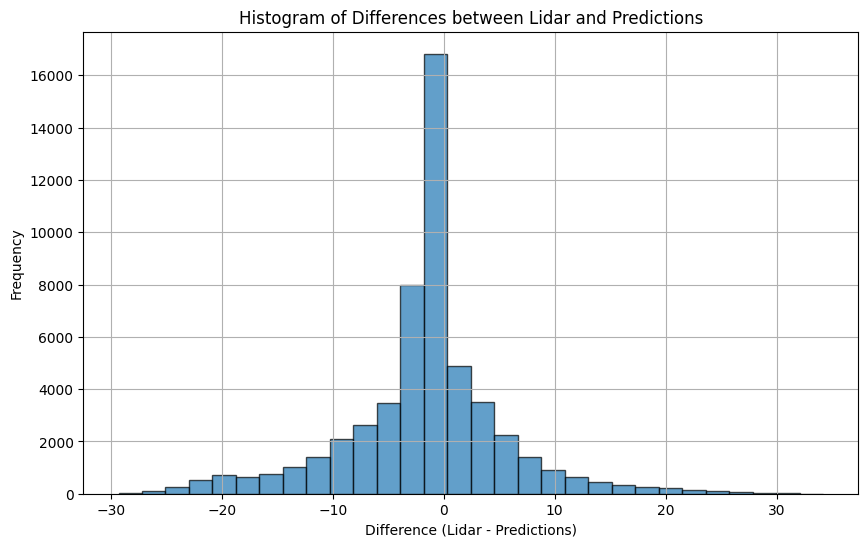

In [ ]:
# Plot difference histogram

# Calculate the differences
df_test_plot['difference'] = df_test_plot['lidar'] - df_test_plot['predicted']

# Create a histogram of the differences
plt.figure(figsize=(10, 6))
plt.hist(df_test_plot['difference'], bins=30, edgecolor='k', alpha=0.7)
plt.title('Histogram of Differences between Lidar and Predictions (test)')
plt.xlabel('Difference (Lidar - Predictions)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [ ]:
# Plot difference histogram

# Calculate the differences
df_train_plot['difference'] = df_train_plot['lidar'] - df_train_plot['predicted']

# Create a histogram of the differences
plt.figure(figsize=(10, 6))
plt.hist(df_train_plot['difference'], bins=30, edgecolor='k', alpha=0.7)
plt.title('Histogram of Differences between Lidar and Predictions (train)')
plt.xlabel('Difference (Lidar - Predictions)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## Map Plot

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

In [ ]:
import geopandas as gpd

# Create a GeoDataFrame
gdf_test = gpd.GeoDataFrame(
    df_test_plot, geometry=gpd.points_from_xy(df_test_plot.x, df_test_plot.y))

# Set the coordinate reference system (CRS) if known, for example, EPSG:4326
gdf_test.set_crs(epsg=25832, inplace=True)

,x,y,lidar,predicted,difference,geometry
0,0.5,0.500000,9.224915,15.671549,-6.446634,POINT (0.5 0.5)
1,0.5,0.501506,9.765671,10.730158,-0.964487,POINT (0.5 0.502)
2,0.5,0.503012,5.369989,10.685282,-5.315293,POINT (0.5 0.503)
3,0.5,0.504518,3.206217,12.701896,-9.495679,POINT (0.5 0.505)
4,0.5,0.506024,4.183727,7.250954,-3.067227,POINT (0.5 0.506)
...,...,...,...,...,...,...
53608,1.0,0.993976,0.000000,2.749290,-2.749290,POINT (1 0.994)
53609,1.0,0.995482,0.000000,3.044570,-3.044570,POINT (1 0.995)
53610,1.0,0.996988,0.000000,2.771816,-2.771816,POINT (1 0.997)
53611,1.0,0.998494,0.000000,3.123534,-3.123534,POINT (1 0.998)


In [ ]:
# Create a GeoDataFrame
gdf_train = gpd.GeoDataFrame(
    df_train_plot, geometry=gpd.points_from_xy(df_train_plot.x, df_train_plot.y))

# Set the coordinate reference system (CRS) if known, for example, EPSG:4326
gdf_train.set_crs(epsg=25832, inplace=True)

/opt/conda/envs/fdl-biomass-env/lib/python3.10/site-packages/matplotlib/collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
/opt/conda/envs/fdl-biomass-env/lib/python3.10/site-packages/contextily/tile.py:623: UserWarning: The inferred zoom level of 28 is not valid for the current tile provider (valid zooms: 0 - 20).
  warnings.warn(msg)


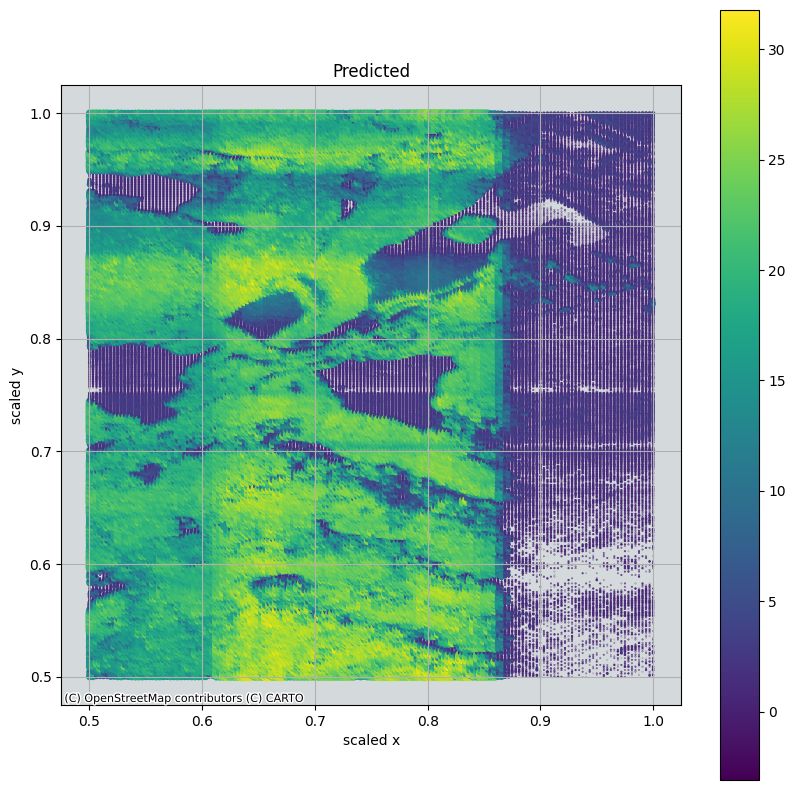

In [ ]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 10))
gdf_test.plot(ax=ax, column='predicted', cmap='viridis', legend=True, markersize=gdf_test['predicted']*1)

# Add the map background using a valid provider
ctx.add_basemap(ax, crs=gdf_test.crs.to_string(), source=ctx.providers.CartoDB.Positron)

# Set the title and labels
ax.set_title('Predicted - test data')
plt.xlabel('scaled x')
plt.ylabel('scaled y')
plt.grid(True)
plt.show()

In [ ]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 10))
gdf_train.plot(ax=ax, column='predicted', cmap='viridis', legend=True, markersize=gdf['predicted']*1)

# Add the map background using a valid provider
ctx.add_basemap(ax, crs=gdf_train.crs.to_string(), source=ctx.providers.CartoDB.Positron)

# Set the title and labels
ax.set_title('Predicted - train data')
plt.xlabel('scaled x')
plt.ylabel('scaled y')
plt.grid(True)
plt.show()